# Camada Gold

Objetivo: responder perguntas sobre o catálogo de cartas com indicadores prontos para leitura.

Cada indicador é um arquivo `.sql` em `sql/` que lê só o schema `silver`. O nome do arquivo vira a tabela `gold.<nome>`.
Os gráficos deste notebook leem apenas as tabelas gold, sem nenhum cálculo novo.

| Tabela gold | Pergunta |
|---|---|
| `indicadores_gerais` | Quais são os números gerais do catálogo? |
| `composicao_catalogo` | Como o catálogo se divide entre Pokémon, Treinadores e Energias? |
| `perfil_por_tipo` | Qual o perfil de cada tipo em HP, recuo e força de ataque? |
| `hp_por_premio` | Um Pokémon ex ou Mega ex compensa os prêmios a mais que entrega? |
| `vantagem_por_tipo` | Atacar com qual tipo dá vantagem contra mais Pokémon? |
| `matriz_fraquezas` | A qual tipo cada tipo de Pokémon costuma ser fraco? |
| `dano_por_custo` | Quanto dano cada energia a mais no custo entrega? |
| `ranking_ataques` | Quais ataques entregam mais dano por energia? |
| `recuo_e_hp` | Pokémon mais resistentes custam mais para recuar? |
| `expansoes` | Como as expansões se diferenciam? |
| `composicao_deck_exemplo` | Como é montado o deck exemplo da competição? |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from pipeline import config
from pipeline.db import conectar, ler_tabela, listar_tabelas
from pipeline.gold import INDICADORES, criar_todos

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)

## 1. Criação das tabelas gold a partir dos arquivos SQL

In [2]:
conexao = conectar(config.BANCO)
criar_todos(conexao)
gold = {nome: ler_tabela(conexao, "gold", nome) for nome in listar_tabelas(conexao, "gold")}
assert sorted(gold) == sorted(INDICADORES)
print(f"{len(gold)} tabelas no schema gold")

11 tabelas no schema gold


Exemplo de arquivo de origem de um indicador:

In [3]:
print((config.PASTA_SQL / "hp_por_premio.sql").read_text(encoding="utf-8"))

-- Pergunta: um Pokémon ex ou Mega ex compensa o risco de entregar mais prêmios ao oponente?
-- Grão: uma linha por estágio de evolução e regra.
-- hp_por_premio = HP médio dividido pelos prêmios que o oponente ganha ao nocautear a carta.
WITH dano_maximo AS (
    SELECT card_id, MAX(dano_base) AS maior_dano
    FROM silver.movimentos
    WHERE tipo_movimento = 'Ataque'
    GROUP BY card_id
)
SELECT
    c.subtipo AS estagio,
    c.regra,
    MAX(c.premios_cedidos) AS premios_cedidos,
    COUNT(*) AS qtd_pokemon,
    ROUND(AVG(c.hp), 1) AS hp_medio,
    ROUND(AVG(c.hp) / MAX(c.premios_cedidos), 1) AS hp_por_premio,
    ROUND(AVG(d.maior_dano), 1) AS maior_dano_medio
FROM silver.cartas AS c
LEFT JOIN dano_maximo AS d ON d.card_id = c.card_id
WHERE c.supertipo = 'Pokémon'
GROUP BY c.subtipo, c.regra
ORDER BY estagio, premios_cedidos



In [4]:
# Padrão visual dos gráficos: marcas finas, grade discreta e uma cor por série
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_SECUNDARIO, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
RAMPA_AZUL = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SECUNDARIO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": TEXTO,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SECUNDARIO,
    "ytick.color": TEXTO_SECUNDARIO,
    "legend.frameon": False,
})


def barras_horizontais(dados, categoria, valor, titulo, rotulo_x, formato="{:.0f}", destaque=None):
    """Barras horizontais ordenadas, com o valor escrito na ponta. 'destaque' pinta uma barra de laranja."""
    dados = dados.sort_values(valor)
    cores = [LARANJA if item == destaque else AZUL for item in dados[categoria]]
    fig, eixo = plt.subplots(figsize=(8, 0.42 * len(dados) + 1))
    barras = eixo.barh(dados[categoria], dados[valor], color=cores, height=0.6)
    eixo.bar_label(barras, labels=[formato.format(v) for v in dados[valor]], padding=4, color=TEXTO, fontsize=9)
    eixo.set_title(titulo)
    eixo.set_xlabel(rotulo_x)
    eixo.grid(axis="y", visible=False)
    eixo.set_axisbelow(True)
    eixo.margins(x=0.12)
    plt.tight_layout()
    plt.show()

## 2. Indicadores gerais

In [5]:
gold["indicadores_gerais"][["indicador", "valor"]]

,indicador,valor
0,Cartas no catálogo,1431.00
1,Pokémon no catálogo,1196.00
2,Pokémon ex ou Mega ex (%),14.00
3,HP médio dos Pokémon,122.40
4,Pokémon com habilidade (%),20.40
5,Ataques no catálogo,1755.00
6,Ataques sem dano (%),17.50
7,Dano médio por energia (ataques de dano fixo),32.70
8,Correlação entre HP e custo de recuo,0.36
9,Pokémon sem fraqueza,39.00


## 3. Composição do catálogo

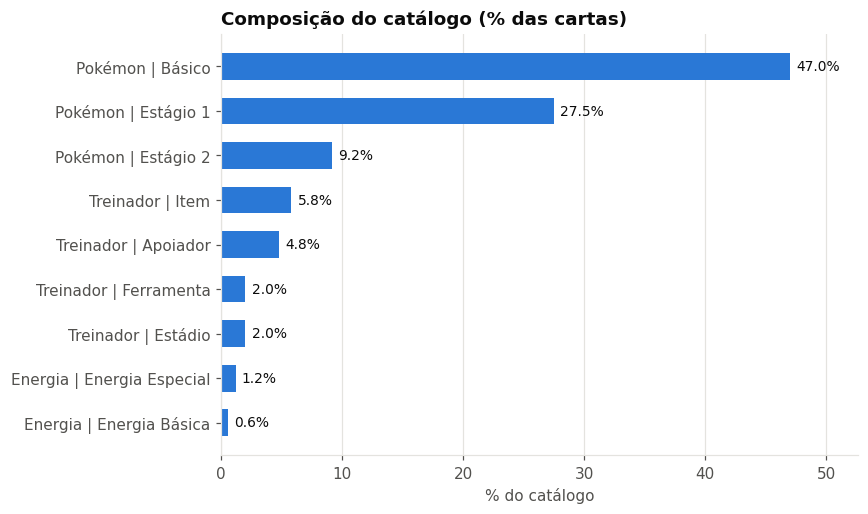

,supertipo,subtipo,qtd_cartas,pct_catalogo
0,Energia,Energia Especial,17,1.2
1,Energia,Energia Básica,8,0.6
2,Pokémon,Básico,672,47.0
3,Pokémon,Estágio 1,393,27.5
4,Pokémon,Estágio 2,131,9.2
5,Treinador,Item,83,5.8
6,Treinador,Apoiador,69,4.8
7,Treinador,Estádio,29,2.0
8,Treinador,Ferramenta,29,2.0


In [6]:
composicao = gold["composicao_catalogo"].assign(rotulo=lambda d: d["supertipo"] + " | " + d["subtipo"])
barras_horizontais(composicao, "rotulo", "pct_catalogo", "Composição do catálogo (% das cartas)", "% do catálogo", "{:.1f}%")
composicao.drop(columns="rotulo")

## 4. Perfil por tipo de Pokémon

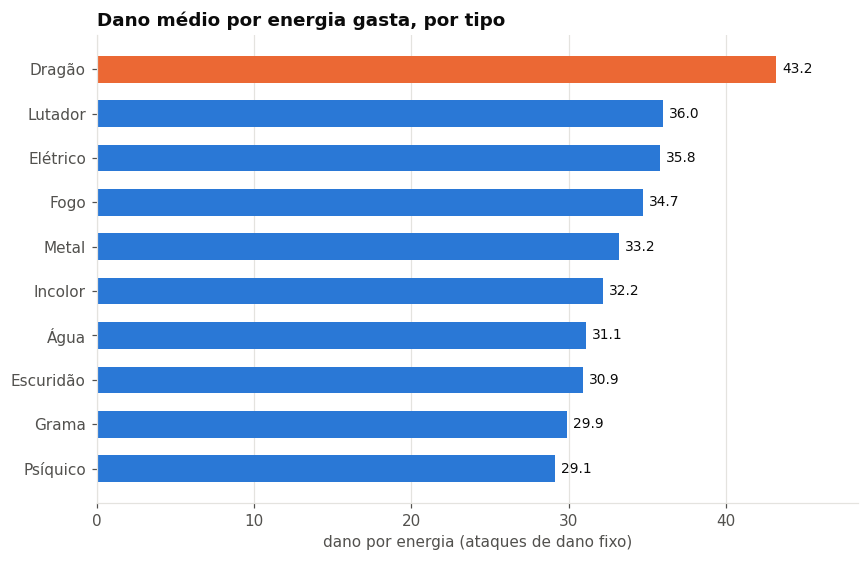

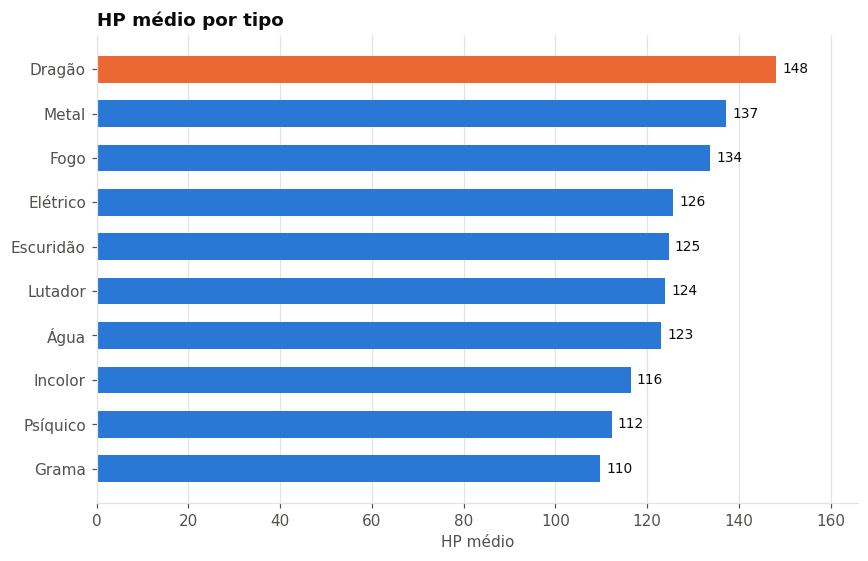

,tipo,qtd_pokemon,hp_medio,hp_mediano,recuo_medio,pct_ex,qtd_ataques_dano_fixo,dano_medio,dano_por_energia
0,Grama,170,109.8,90.0,1.52,10.0,174,58.3,29.9
1,Psíquico,162,112.3,90.0,1.51,12.3,154,60.3,29.1
2,Água,158,123.1,100.0,1.77,11.4,184,67.2,31.1
3,Escuridão,137,124.7,100.0,1.61,15.3,156,66.0,30.9
4,Lutador,132,123.9,110.0,1.94,9.8,162,73.2,36.0
5,Fogo,116,133.7,110.0,1.80,17.2,131,75.7,34.7
6,Incolor,115,116.4,100.0,1.45,14.8,116,65.9,32.2
7,Elétrico,86,125.7,110.0,1.22,20.9,98,79.7,35.8
8,Metal,81,137.3,130.0,2.05,17.3,97,78.6,33.2
9,Dragão,39,148.2,120.0,1.82,23.1,47,103.4,43.2


In [7]:
perfil = gold["perfil_por_tipo"]
barras_horizontais(perfil, "tipo", "dano_por_energia", "Dano médio por energia gasta, por tipo",
                   "dano por energia (ataques de dano fixo)", "{:.1f}", destaque="Dragão")
barras_horizontais(perfil, "tipo", "hp_medio", "HP médio por tipo", "HP médio", "{:.0f}", destaque="Dragão")
perfil

## 5. Um Pokémon ex compensa os prêmios que entrega?

Ao nocautear um Pokémon comum o oponente pega 1 prêmio, um ex entrega 2 e um Mega ex entrega 3.
O indicador `hp_por_premio` mostra quanto HP o oponente precisa tirar para cada prêmio que ganha.

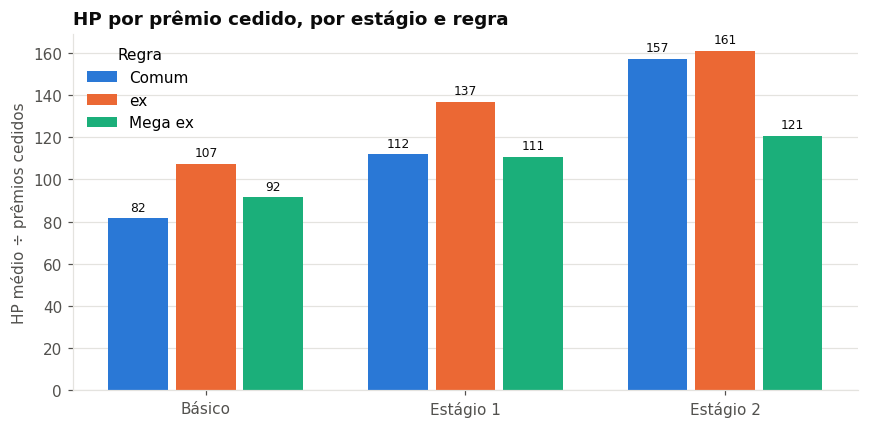

,estagio,regra,premios_cedidos,qtd_pokemon,hp_medio,hp_por_premio,maior_dano_medio
0,Básico,Comum,1,599,81.5,81.5,41.5
1,Básico,ex,2,60,214.5,107.3,140.3
2,Básico,Mega ex,3,13,274.6,91.5,170.8
3,Estágio 1,Comum,1,336,111.8,111.8,76.2
4,Estágio 1,ex,2,44,273.4,136.7,163.3
5,Estágio 1,Mega ex,3,13,332.3,110.8,196.7
6,Estágio 2,Comum,1,94,157.2,157.2,126.3
7,Estágio 2,ex,2,25,322.0,161.0,193.6
8,Estágio 2,Mega ex,3,12,361.7,120.6,179.1


In [8]:
premio = gold["hp_por_premio"]
tabela = premio.pivot(index="estagio", columns="regra", values="hp_por_premio")[["Comum", "ex", "Mega ex"]]

fig, eixo = plt.subplots(figsize=(8, 4))
largura = 0.26
for i, (regra, cor) in enumerate(zip(tabela.columns, [AZUL, LARANJA, VERDE_AGUA])):
    posicoes = [x + (i - 1) * largura for x in range(len(tabela))]
    barras = eixo.bar(posicoes, tabela[regra], width=largura - 0.03, color=cor, label=regra)
    eixo.bar_label(barras, fmt="%.0f", padding=3, fontsize=8, color=TEXTO)
eixo.set_xticks(range(len(tabela)), tabela.index)
eixo.set_title("HP por prêmio cedido, por estágio e regra")
eixo.set_ylabel("HP médio ÷ prêmios cedidos")
eixo.grid(axis="x", visible=False)
eixo.set_axisbelow(True)
eixo.legend(title="Regra", loc="upper left")
plt.tight_layout()
plt.show()
premio

## 6. Vantagem de tipo

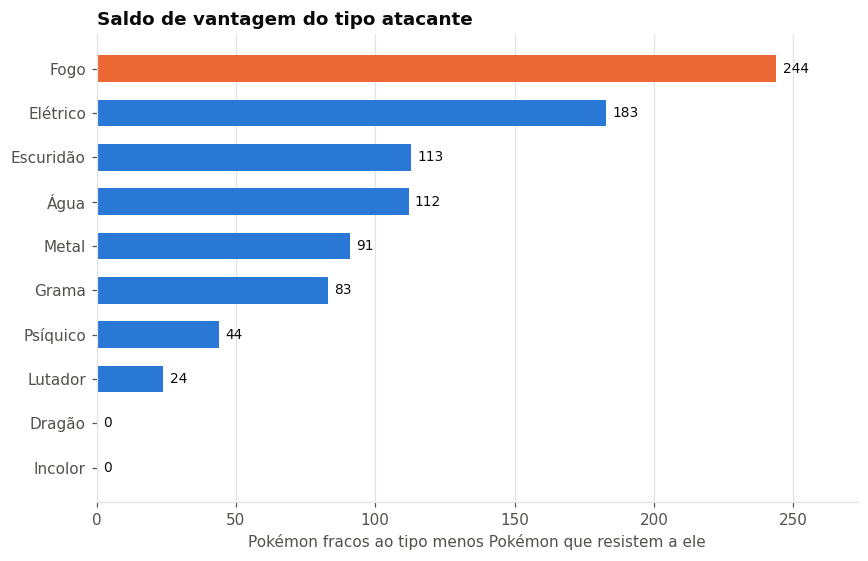

,tipo_atacante,qtd_fracos,qtd_resistentes,saldo,pct_catalogo_fraco
0,Fogo,244,0,244,20.4
1,Elétrico,183,0,183,15.3
2,Escuridão,113,0,113,9.4
3,Água,112,0,112,9.4
4,Metal,91,0,91,7.6
5,Grama,159,76,83,13.3
6,Psíquico,44,0,44,3.7
7,Lutador,211,187,24,17.6
8,Dragão,0,0,0,0.0
9,Incolor,0,0,0,0.0


In [9]:
vantagem = gold["vantagem_por_tipo"]
barras_horizontais(vantagem, "tipo_atacante", "saldo",
                   "Saldo de vantagem do tipo atacante", "Pokémon fracos ao tipo menos Pokémon que resistem a ele",
                   destaque="Fogo")
vantagem

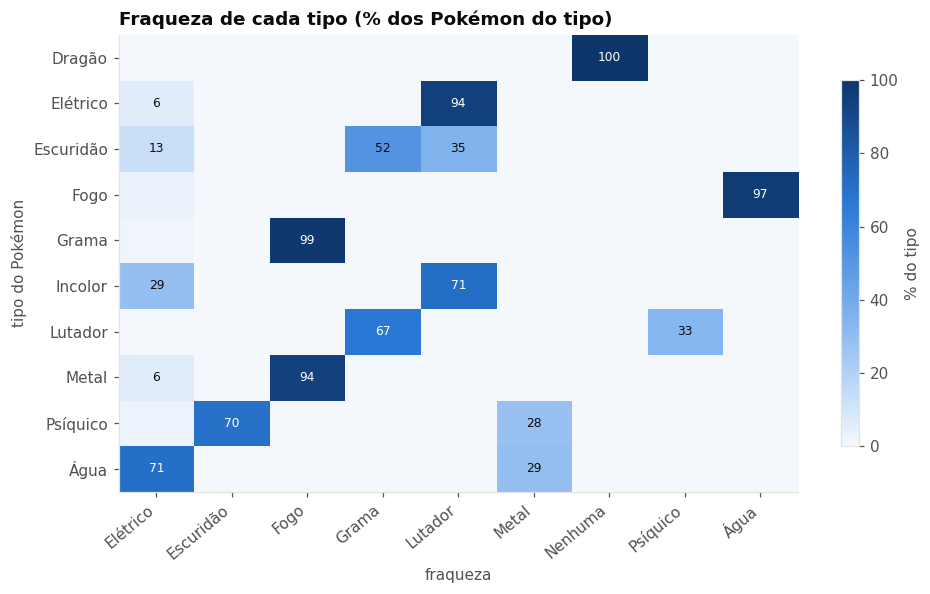

In [10]:
matriz = gold["matriz_fraquezas"].pivot(index="tipo", columns="fraqueza", values="pct_do_tipo").fillna(0)

fig, eixo = plt.subplots(figsize=(9, 5.5))
imagem = eixo.imshow(matriz.values, cmap=RAMPA_AZUL, vmin=0, vmax=100, aspect="auto")
eixo.set_xticks(range(len(matriz.columns)), matriz.columns, rotation=40, ha="right")
eixo.set_yticks(range(len(matriz.index)), matriz.index)
for linha in range(matriz.shape[0]):
    for coluna in range(matriz.shape[1]):
        valor = matriz.iat[linha, coluna]
        if valor >= 5:
            eixo.text(coluna, linha, f"{valor:.0f}", ha="center", va="center", fontsize=8,
                      color="white" if valor > 55 else TEXTO)
eixo.grid(False)
eixo.set_title("Fraqueza de cada tipo (% dos Pokémon do tipo)")
eixo.set_xlabel("fraqueza")
eixo.set_ylabel("tipo do Pokémon")
fig.colorbar(imagem, ax=eixo, label="% do tipo", shrink=0.8)
plt.tight_layout()
plt.show()

## 7. Custo de energia e dano

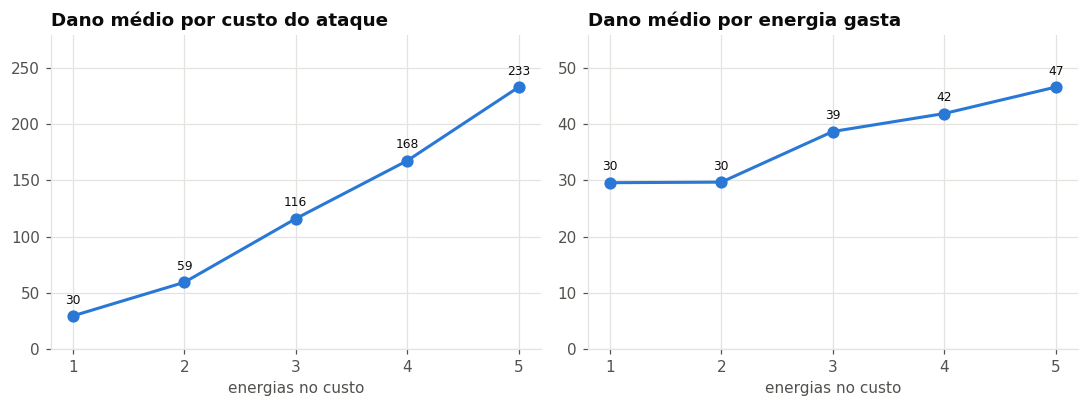

,custo_total,qtd_ataques,pct_sem_dano,qtd_dano_fixo,dano_medio,dano_mediano,dano_maximo,dano_medio_por_energia
0,0,5,40.0,3,16.7,10.0,30,NaN
1,1,770,31.3,472,29.6,20.0,250,29.6
2,2,504,6.0,429,59.4,50.0,280,29.7
3,3,401,8.0,349,116.0,100.0,330,38.7
4,4,66,1.5,63,167.5,150.0,350,41.9
5,5,9,22.2,7,232.9,240.0,270,46.6


In [11]:
custo = gold["dano_por_custo"].query("custo_total > 0")

fig, (eixo_a, eixo_b) = plt.subplots(1, 2, figsize=(10, 3.8))
for eixo, coluna, titulo in [
    (eixo_a, "dano_medio", "Dano médio por custo do ataque"),
    (eixo_b, "dano_medio_por_energia", "Dano médio por energia gasta"),
]:
    eixo.plot(custo["custo_total"], custo[coluna], color=AZUL, linewidth=2, marker="o", markersize=7)
    for x, y in zip(custo["custo_total"], custo[coluna]):
        eixo.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=TEXTO)
    eixo.set_title(titulo)
    eixo.set_xlabel("energias no custo")
    eixo.set_xticks(custo["custo_total"])
    eixo.set_ylim(0, custo[coluna].max() * 1.2)
plt.tight_layout()
plt.show()
gold["dano_por_custo"]

## 8. Ataques mais eficientes

In [12]:
gold["ranking_ataques"]

,posicao,pokemon,tipo,estagio,regra,ataque,custo,custo_total,dano_base,dano_por_energia,tem_efeito
0,1,Palafin ex,Água,Estágio 1,ex,Giga Impact,{W},1,250,250.0,True
1,2,Ceruledge,Fogo,Estágio 1,Comum,Infernal Slash,{R},1,220,220.0,True
2,3,Decidueye,Grama,Estágio 2,Comum,Power Shot,{G},1,170,170.0,True
3,3,Greninja ex,Lutador,Estágio 2,ex,Shinobi Blade,{W},1,170,170.0,True
4,5,Medicham,Lutador,Estágio 1,Comum,Seventh Kick,{F},1,150,150.0,True
5,6,Slaking ex,Incolor,Estágio 2,ex,Great Swing,●●,2,280,140.0,True
6,7,Diggersby,Incolor,Estágio 1,Comum,Earthquake,●,1,140,140.0,True
7,8,Mega Lucario ex,Lutador,Estágio 1,Mega ex,Mega Brave,{F}{F},2,270,135.0,True
8,9,Cynthia's Garchomp ex,Lutador,Estágio 2,ex,Draconic Buster,{F}{F},2,260,130.0,True
9,9,Vikavolt,Elétrico,Estágio 2,Comum,Giga Railgun,{L}{L},2,260,130.0,True


## 9. Recuo e HP

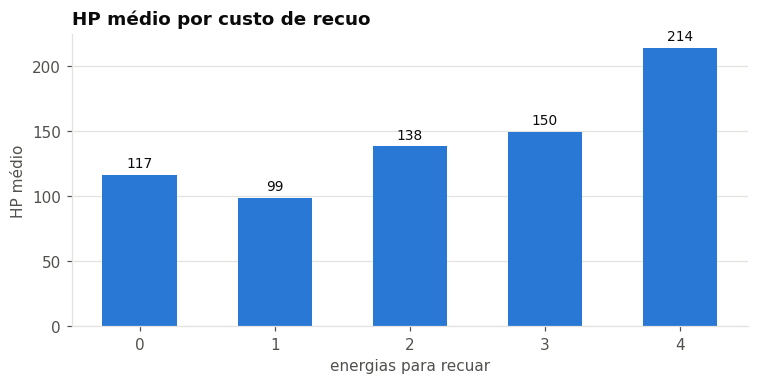

,recuo,qtd_pokemon,pct_pokemon,hp_medio,pct_ex
0,0,38,3.2,116.6,21.1
1,1,589,49.2,98.6,9.3
2,2,363,30.4,138.4,18.2
3,3,163,13.6,149.6,14.1
4,4,43,3.6,214.4,34.9


In [13]:
recuo = gold["recuo_e_hp"].assign(recuo=lambda d: d["recuo"].astype(str))
fig, eixo = plt.subplots(figsize=(7, 3.6))
barras = eixo.bar(recuo["recuo"], recuo["hp_medio"], color=AZUL, width=0.55)
eixo.bar_label(barras, fmt="%.0f", padding=3, fontsize=9, color=TEXTO)
eixo.set_title("HP médio por custo de recuo")
eixo.set_xlabel("energias para recuar")
eixo.set_ylabel("HP médio")
eixo.grid(axis="x", visible=False)
eixo.set_axisbelow(True)
plt.tight_layout()
plt.show()
gold["recuo_e_hp"]

## 10. Expansões

In [14]:
gold["expansoes"]

,expansao,qtd_cartas,qtd_pokemon,qtd_treinador,qtd_energia,pct_ex_entre_pokemon,hp_medio_pokemon
0,DRI,178,158,19,1,10.1,114.8
1,MEG,126,112,14,0,8.9,121.0
2,ASC,124,116,8,0,19.8,133.9
3,TWM,95,72,21,2,19.4,126.9
4,SSP,95,73,21,1,20.5,129.2
5,PFL,94,84,10,0,11.9,123.0
6,WHT,85,78,6,1,7.7,109.0
7,JTG,85,71,13,1,14.1,121.0
8,BLK,84,78,5,1,7.7,110.4
9,CRI,83,71,9,3,11.3,120.7


## 11. Deck exemplo da competição

In [15]:
gold["composicao_deck_exemplo"]

,supertipo,subtipo,copias,cartas_distintas,pct_deck,cartas
0,Energia,Energia Básica,35,1,58.3,Basic {W} Energy
1,Treinador,Apoiador,10,3,16.7,"Cyrano, Lillie's Determination, Waitress"
2,Pokémon,Básico,6,2,10.0,"Kyogre, Snover"
3,Treinador,Item,4,1,6.7,Mega Signal
4,Pokémon,Estágio 1,4,1,6.7,Mega Abomasnow ex
5,Treinador,Ferramenta,1,1,1.7,Maximum Belt


In [16]:
conexao.close()

## 12. Insights

1. **O catálogo é dominado por Pokémon.** São 1431 cartas, 83,6% Pokémon, 14,7% Treinadores e 1,7% Energias. Quase metade do catálogo (47%) são Pokémon básicos.
2. **Pokémon ex compensam, Mega ex nem tanto.** Em todos os estágios o ex exige mais HP por prêmio que o Pokémon comum (Básico: 107 contra 82) e bate muito mais forte (maior dano médio de 140 contra 42 no Básico). Já o Mega ex entrega 3 prêmios e fica abaixo do ex em HP por prêmio nos três estágios (Estágio 2: 121 contra 161).
3. **No Estágio 2 o ex quase não ganha em resistência.** O Estágio 2 comum já tem 157 de HP por prêmio, contra 161 do ex. A vantagem do ex nesse estágio está no dano (194 contra 126), não na sobrevivência.
4. **Fogo é o melhor tipo para atacar.** 244 Pokémon (20,4% do catálogo) são fracos a Fogo e nenhum resiste a ele. Lutador tem muitos alvos fracos (211), mas 187 Pokémon resistem, o que zera quase toda a vantagem.
5. **Só existem resistências a Lutador e Grama.** Todo o resto do catálogo não tem resistência, o que torna esses dois tipos os mais arriscados de usar no ataque.
6. **Dragão é o tipo mais forte, mas o mais raro.** Tem o maior HP médio (148), o maior dano por energia (43) e nenhum dos 39 Pokémon tem fraqueza. Em compensação, são só 3,3% dos Pokémon. Grama e Psíquico são os tipos com menor HP e menor dano por energia.
7. **Ataques caros rendem mais por energia.** O dano por energia sobe de 30 (1 ou 2 energias) para 39 (3 energias) e 42 (4 energias). Com 5 energias chega a 47, mas são só 7 ataques nessa faixa. Além disso, 31% dos ataques de 1 energia não causam dano: são ataques de suporte.
8. **Dano alto e barato sempre tem condição.** Os 20 ataques mais eficientes têm texto de efeito, em geral uma restrição ou uma exigência para funcionar. No total, 55% dos ataques de dano fixo têm algum efeito.
9. **HP e recuo andam juntos, mas de forma moderada.** A correlação é de 0,36. Metade dos Pokémon recua com 1 energia, e os de recuo 4 têm HP médio de 214.
10. **O deck exemplo é quase todo energia.** 35 das 60 cartas (58%) são Energia básica de Água, para sustentar Mega Abomasnow ex. Só 10 cartas são Pokémon, um ponto de partida simples para quem for montar um agente.
11. **Observação sobre os dados.** Pokémon Tera trocam de tipo: Greninja ex Tera Lutador aparece como Lutador, mas seus ataques custam energia de Água. Por isso o tipo da carta nem sempre é o tipo de energia que ela usa.